

```
# This is formatted as code
```


# Advance DL Mid Term Exam

**Name: Saiyedul Abrar**

**Course Email: saiyedul.abrar1430@gmail.com**

**Dataset:** [Faces: Age Detection from Images](https://www.kaggle.com/datasets/arashnic/faces-age-detection-dataset)


## End of Assignment

Before submitting:
- Run all cells from top to bottom.  
- Check that all answer sections are filled.  
- Instruction video অনুযায়ী আমাদের দেয়া Colab ফাইলটি থেকে প্রথম একটি Save copy in drive করে নিবা। এরপর Google colab এর মধ্যে কোডগুলো করবে এবং সেই ফাইলটি ‘Anyone with the link’ & ‘View’ Access দিয়ে ফাইলটির Shareble Link টি সাবমিট করবে।


# Question 01: [ Marks 10 ]

## Explain the concept of Convolutional Neural Networks (CNNs) in detail. Describe why CNNs are preferred over fully connected Artificial Neural Networks for image data, how local connectivity and weight sharing work, and how these ideas help in extracting spatial features from face images used for age-group detection.


# Write Answer 01:

A Convolutional Neural Network (CNN) is a neural network designed to process grid-like data such as an image. An image is represented by pixel values, and a CNN learns small patterns first and combines them into increasingly complex patterns. convolutional layer slides a small learnable filter over the image. At each location it multiplies the filter values by the corresponding pixel values, adds the products, and produces one number. Repeating this operation creates a feature map. Early filters commonly learn edges, corners, and simple colour contrasts; deeper filters combine these into eyes, noses, hair, wrinkles, and face shape.CNNs are preferred to a fully connected network for images for three main reasons:

1. Local connectivity
2. Weight sharing
3. Hierarchical spatial features

For face age-group detection, the first layers can detect contours and shading, intermediate layers can detect facial components and skin texture, and later layers can combine these features to distinguish Young, Middle, and Old faces. A fully connected network would flatten all pixels immediately, lose local spatial structure, require many more parameters, and be more prone to overfitting. CNNs do not make age prediction automatically invariant to every pose or illumination change, so augmentation and normalization are still important.



# Question 02: [ Marks 10 ]

## Describe the architecture of a basic CNN in detail. Explain the role of each component (convolutional layer, activation function, pooling layer, flatten layer, and fully connected layer). Also discuss how increasing the number of convolutional layers and filters affects feature extraction, model performance, and overfitting.


# Write Answer 02:

A basic CNN can be organized as:

From Input image to Convolution to Activation to Pooling to Convolution to Activation to Pooling and Flatten to a Fully connected then Output

Convolutional layer learns filters (kernels) that scan local regions and produce feature maps. The number of filters is the number of output channels.

Activation function usually ReLU, ReLU(x) = max(0, x). It adds non-linearity, allowing the network to learn complex relationships rather than only a linear transformation.

Pooling layer downsamples each feature map. For example, 2×2 max pooling with stride 2 keeps the largest value in each 2×2 region. It reduces spatial size and computation and gives limited tolerance to small translations.

Flatten layer reshapes the final tensor from (channels, height, width) into one vector per image. It does not learn parameters.

Fully connected layer combines the extracted features. The final fully connected layer has three outputs, one for each age group; softmax probabilities can be obtained from these logits.

Increasing the number of convolutional layers gives a larger effective receptive field and allows hierarchical features: edges, textures, facial parts, and complete age related patterns. Increasing filters gives the network more feature detectors at a given depth. These changes can improve accuracy when the original model is under-capacity, but they increase memory, computation, and the number of parameters. A large model may overfit, especially if the training set is small or imbalanced. Batch normalization, dropout, data augmentation, weight decay, early stopping, and transfer learning can control this. More layers also make optimization harder, so good initialization, normalization, and possibly residual connections are useful.


# Question 03: [Marks 5]

## Explain what a filter (kernel) is in a CNN and how feature maps are generated during the convolution operation. Discuss how different filters can detect edges, textures, wrinkles, and other facial patterns that are useful for classifying a face as Young, Middle, or Old.


# Write Answer 03:

A filter or kernel is a small matrix of learnable weights, such as 3×3, together with a bias. It is moved across the input using a chosen stride and padding. At each position, the element-wise products between the kernel and the local image patch are summed with the bias. The resulting values form a feature map. One filter produces one output channel; a layer with 32 filters produces 32 feature maps. Different learned filters respond to different patterns. In early layers, filters may respond to horizontal or vertical edges, corners, colour transitions, and simple textures. In later layers, combinations of these responses can represent skin texture, hair, eyes, mouth shape, forehead lines, and wrinkles. The network learns which patterns are useful from labelled examples rather than being given handcrafted rules. A final classifier combines the feature maps and produces scores for Young, Middle, and Old. A wrinkle response alone is not a decision: lighting, makeup, pose, and expression can also produce similar patterns, so the CNN must use many features together.


# Question 04: [ Marks 5 ]

## A CNN takes an image as a grid of numbers. Explain in simple words what an RGB face image is and what the shape 64×64×3 means. Also explain why we usually resize all face images to the same height and width before training an age-detection CNN.


# Write Answer 04:
An RGB image stores three colour channels for every pixel: red, green, and blue. Therefore, 64×64×3 means height = 64 pixels, width = 64 pixels, and 3 channels. There are 64 × 64 × 3 = 12,288 scalar pixel values. A grayscale image would have one channel, while RGB has three. We resize all face images to a common height and width because a mini batch is stored as one tensor and tensor dimensions must agree. A fixed size also makes the number of operations and the CNN architecture predictable. Resizing improves batching and allows the same fully connected input size for every example. It may remove fine detail or distort aspect ratio, so a reasonable size, aspect ratio aware croppin or padding, and augmentation should be used. Pixel values are then converted to tensors and normalized so optimization is more stable.


# Question 05: [ Marks 10 ]

## Explain padding and stride in CNNs in detail. Then explain the convolutional output size formula and what each symbol in the formula means. You do not need to derive the formula. Show how the output height and width change when you use valid padding, same padding, or a larger stride. Also explain why padding is useful when working with cropped face images.


# Write Answer 05:

Padding adds extra pixels around the input border, usually zeros. With valid padding, no border is added; with same padding, padding is selected so that a stride-1 convolution keeps the height and width unchanged for an odd kernel such as 3×3. Padding lets filters see border pixels in a more balanced way and prevents repeated shrinking of the feature maps. This is especially useful for cropped face images because important information such as ears, hair, or the outline of the face may lie near an edge.

Stride is the number of pixels by which the kernel moves horizontally and vertically. Stride 1 evaluates every nearby position. A larger stride skips positions, reduces the output size, and performs downsampling, but may discard spatial detail.

For one spatial dimension, the convolution or pooling output-size formula is:

O = {N+2P - D(K-1)-1}{S}+1

where N is the input size, K is kernel size, P is padding on each side, S is stride, D is dilation, and O is output size. For ordinary convolution, D=1, when O = floor((N+2P-K)/S)+1.For example,
 N=64, K=3, S=1: P=0 gives 62. P=1 gives N=64. With K=3, P=1, S=2, the output is 32. Thus valid padding shrinks the map, same padding preserves it for stride 1, and a larger stride shrinks it more quickly.


# Question 06: [ Marks 10 ]

## Explain the concept of pooling in CNNs. Compare MaxPooling and AveragePooling in terms of operation, advantages, and impact on feature extraction. Discuss how pooling helps in reducing overfitting and computational complexity when training an age-detection CNN on thousands of face images.


# Write Answer 06:
Pooling summarizes values in a local window and moves that window across a feature map. It has no learned weights. For a 2×2 window with stride 2, height and width are usually halved.

MaxPooling returns the largest value in each window. It preserves the strongest evidence that a feature is present and is relatively robust to small translations. It is useful when a strong edge or wrinkle response is sufficient, but it discards all other values and can discard subtle information.

AveragePooling returns the mean of the values in each window. It retains overall activation information and produces smoother maps, but a strong local feature may be diluted by surrounding low values.

Pooling reduces height and width, so later layers require fewer multiply-add operations and less memory. It also reduces the number of values entering the classifier and can reduce overfitting by limiting the model's sensitivity to exact pixel locations. However, pooling is not a complete solution for overfitting and excessive pooling can remove age related fine details. Modern CNNs may also use strided convolution or global average pooling. For thousands of face images, pooling is most effective together with augmentation, normalization, dropout, weight decay, and validation-based early stopping.


# Question 07: [ Marks 10 ]

## Describe the convolution operation in CNNs with a complete step-by-step numerical example. Use a small input matrix (for example 5×5) and a 3×3 filter, apply a chosen stride and padding, and show how each value of the output feature map is calculated. Also compute the output size using the standard formula.



# Write Answer 07:

Consider a 5 × 5 input matrix and a 3 × 3 filter:

Input X:              

1  2  3  4  5         
6  7  8  9  10        
11 12 13 14 15        
16 17 18 19 20
21 22 23 24 25

Filter K:

1   0  -1

1   0  -1

1   0  -1

Here, stride S = 1 and padding P = 0.

The output size is:


Output = ((N + 2P - K) / S) + 1

= ((5 + 0 - 3) / 1) + 1

= 3

Therefore, the output feature map is 3 × 3.

For the first 3 × 3 region:


1  2  3

6  7  8

11 12 13


The convolution result is:


(1×1)+(2×0)+(3×−1) +(6×1)+(7×0)+(8×−1)+(11×1)+(12×0)+(13×−1)

= -6


The filter moves across the input matrix and produces:


-6  -6  -6

-6  -6  -6

-6  -6  -6

Thus, the final output feature map is 3 × 3. The filter detects vertical changes or edges in the image. If padding P = 1 were used, the output size would remain 5 × 5.


# Question 08: [ Marks 10 ]

## A resized face image of size 64×64×3 is passed through a CNN with the following layers. Clearly show calculations for the output size after each layer using appropriate formulas: (1) Convolution: 16 filters of size 3×3, stride = 1, padding = 1; (2) MaxPooling of size 2×2, stride = 2; (3) Convolution: 32 filters of size 3×3, stride = 1, padding = 0; (4) MaxPooling of size 2×2, stride = 2. Also state the shape of the tensor just before flattening and the number of values that enter the fully connected layer.


# Write Answer 08:

Use the ordinary formula O =((N + 2P − K)/S) + 1 for a convolution and O =((N + 2P − K)/S) + 1 for pooling.

1. Input: (H,W,C) = (64,64,3).
2. Convolution 1: K=3, S=1, P=1, 16 filters:
H_out=W_out=((64+2−3)/1)+1=64. Shape = 64×64×16.
3. 2×2 max pooling: K=2, S=2, P=0:
H_out=W_out=((64−2)/2)+1=32. Shape = 32×32×16.
4. Convolution 2: K=3, S=1, P=0, 32 filters:
H_out=W_out=((32−3)/1)+1=30. Shape = 30×30×32.
5. 2×2 max pooling: K=2, S=2, P=0:
H_out=W_out=((30−2)/2)+1=15. Shape = 15×15×32.

Therefore, immediately before flattening the tensor is 15×15×32, and the fully connected layer receives 15×15×32 = 7,200 values per image. In PyTorch's channel-first format, the same shape is (batch_size, 32, 15, 15) and flattening starts at dimension 1.


# Question 09: [ Marks 10 ]

## The Faces Age Detection dataset (https://www.kaggle.com/datasets/arashnic/faces-age-detection-dataset) contains 19,906 face images from the Indian Movie Face database (IMFDB). Each image has an ID and a Class label belonging to one of three age groups: Young, Middle, and Old. Discuss the challenges of this dataset such as pose, illumination, expression, occlusion, makeup, and possible class imbalance. Explain how CNN design choices such as data augmentation, normalization, dropout, and class weighting can address these issues. Also justify why this problem is treated as a 3-class classification task rather than continuous age regression.


# Write Answer 09:

The dataset contains face images labelled into three broad groups. It is challenging because faces can differ in pose (frontal, profile, tilted), illumination (dark, bright, shadows, colour cast), expression, occlusion (glasses, hair, hands, masks), makeup, hairstyle, camera quality, and crop. Age appearance also varies by identity, gender, ethnicity, health, and social context. A label may be noisy when a person's apparent age does not match the broad class boundary. The classes may be imbalanced, so accuracy alone can hide poor performance on a minority group.

Useful remedies include:

Augmentation: small rotations, horizontal flips when appropriate, translations, random crops/resizing, brightness/contrast changes, and mild colour jitter improve robustness. Augmentation should not create unrealistic faces or change the label.

Normalization:scale pixels and normalize each channel using training-set statistics. This gives better conditioned inputs and more stable gradients.

Dropout and regularization: dropout in the classifier, weight decay, early stopping, and a suitable model size reduce co-adaptation and overfitting. Batch normalization can stabilize deep blocks.

Class weighting or balanced sampling: estimate class frequencies on the training split and give larger loss weights to rare classes, or sample classes more evenly. Report per class precision, recall, F1, and a confusion matrix in addition to accuracy.

This is a 3 class classification problem because the supplied target is Young, Middle, or Old. The labels do not provide an exact chronological age and the class boundaries are discrete. A softmax classifier therefore estimates three class probabilities and cross-entropy is appropriate. Continuous age regression would require reliable numeric ages and a different target; it could optionally be a separate task if exact ages were available, but it is not justified by these labels alone.


# Question 10: [ Marks 20 ]

## Design and implement a Convolutional Neural Network (CNN) for age-group classification on the Faces Age Detection dataset using PyTorch.
Use the official dataset from https://www.kaggle.com/datasets/arashnic/faces-age-detection-dataset
The CSV file has columns **ID** and **Class**, where Class is one of **Young**, **Middle**, or **Old**.

Complete the following **image pipeline** step by step. For each part, write the code and a short explanation of what that step does.

### Part A: Load the data  [4 marks]
Download / unzip the dataset. Read the CSV file and connect each image ID to its age-group label. Show a few sample images with their labels.

### Part B: Preprocess the images  [4 marks]
Resize all images to the same size (for example 64×64 or 128×128). Convert them to tensors, scale pixel values (normalization), and encode the labels Young, Middle, Old as 0, 1, 2.

### Part C: Split and batch  [3 marks]
Split the data into training and validation sets. Create DataLoaders so that the model receives images in small batches.

### Part D: Build the CNN  [5 marks]
Build a CNN with four convolutional blocks. Each block should have two convolution layers, then activation and normalization, and a pooling layer at the end. Increase the number of filters across blocks. After the convolutional part, flatten the feature maps and add fully connected layers with dropout. The final layer must have 3 outputs.

### Part E: Train and evaluate  [4 marks]
Choose a loss function and an optimizer. Train the model, plot or print training/validation loss or accuracy, and briefly explain the role of each part of this pipeline.


# Write Answer 10:

## Part A: Load the data


## Part B: Preprocess the images


## Part C: Split and batch


## Part D: Build the CNN


## Part E: Train and evaluate


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader, random_split

import kagglehub


In [2]:
path = kagglehub.dataset_download(
    "arashnic/faces-age-detection-dataset"
)

print("path:", path)
print(os.listdir(path))

TRAIN_PATH = os.path.join(path, "faces", "Train")
CSV_PATH = os.path.join(path, "faces", "train.csv")

print("Train path:", TRAIN_PATH)
print("CSV path:", CSV_PATH)


Using Colab cache for faster access to the 'faces-age-detection-dataset' dataset.
path: /kaggle/input/faces-age-detection-dataset
['faces', 'faces_02']
Train path: /kaggle/input/faces-age-detection-dataset/faces/Train
CSV path: /kaggle/input/faces-age-detection-dataset/faces/train.csv


In [3]:
full_df = pd.read_csv(CSV_PATH)

print(full_df.head())
print(full_df["Class"].value_counts())

          ID   Class
0    377.jpg  MIDDLE
1  17814.jpg   YOUNG
2  21283.jpg  MIDDLE
3  16496.jpg   YOUNG
4   4487.jpg  MIDDLE
Class
MIDDLE    10804
YOUNG      6706
OLD        2396
Name: count, dtype: int64


In [21]:
# Part B

SAMPLES_PER_CLASS = 2000

parts = []

for class_name in ["YOUNG", "MIDDLE", "OLD"]:
    class_data = full_df[full_df["Class"] == class_name]
    parts.append(
        class_data.sample(
            n=min(SAMPLES_PER_CLASS, len(class_data)),
            random_state=42
        )
    )

df = pd.concat(parts).sample(frac=1, random_state=42).reset_index(drop=True)

print(df["Class"].value_counts())
print("Total selected images:", len(df))

Class
YOUNG     2000
MIDDLE    2000
OLD       2000
Name: count, dtype: int64
Total selected images: 6000


In [6]:
class_to_index = {
    "YOUNG": 0,
    "MIDDLE": 1,
    "OLD": 2
}

df["label"] = df["Class"].map(class_to_index)


transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [7]:
class FaceDataset(Dataset):

    def __init__(self, dataframe, root_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_name = str(row["ID"])


        if not image_name.lower().endswith((".jpg", ".jpeg", ".png")):
            image_name = image_name + ".jpg"

        image_path = os.path.join(self.root_dir, image_name)
        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(int(row["label"]), dtype=torch.long)
        return image, label


dataset = FaceDataset(
    dataframe=df,
    root_dir=TRAIN_PATH,
    transform=transform
)

print("Dataset size:", len(dataset))


Dataset size: 6000


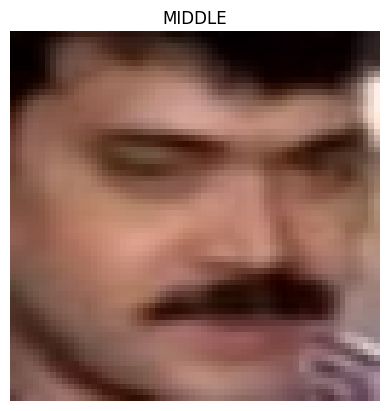

In [14]:
image, label = dataset[22]
image = image * 0.5 + 0.5

plt.imshow(image.permute(1, 2, 0).clamp(0, 1))

title_key = list(class_to_index.keys())[label.item()]
plt.title(title_key)
plt.axis("off")
plt.show()

In [16]:
# Part C

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Using device:", device)

train_size = int(0.8 * len(dataset))
validation_size = len(dataset) - train_size

train_dataset, validation_dataset = random_split(
    dataset,
    [train_size, validation_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))


Using device: cpu
Training images: 4800
Validation images: 1200


In [17]:
# PArt D

class AgeCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(16),
            nn.Conv2d(16, 16, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(16),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 3)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = AgeCNN().to(device)
print(model)


AgeCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU()
    (9): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(32, 64, kernel

In [18]:
# Part E

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 10

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    print(
        f"Epoch {epoch + 1}/{EPOCHS}, "
        f"Training Loss: {average_loss:.4f}"
    )


Epoch 1/10, Training Loss: 1.0017
Epoch 2/10, Training Loss: 0.8972
Epoch 3/10, Training Loss: 0.8258
Epoch 4/10, Training Loss: 0.7663
Epoch 5/10, Training Loss: 0.7083
Epoch 6/10, Training Loss: 0.6549
Epoch 7/10, Training Loss: 0.6211
Epoch 8/10, Training Loss: 0.5776
Epoch 9/10, Training Loss: 0.5252
Epoch 10/10, Training Loss: 0.4886


In [20]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in validation_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

accuracy = correct / total
print("Validation Accuracy:", accuracy*100)


Validation Accuracy: 70.0


### Explanation

The dataset is downloaded with kagglehub. The CSV file is loaded from the faces folder, and the images are loaded from faces/Train. A balanced subset of images per class is used to reduce runtime. The images are resized to 64×64 and normalized. The CNN has four convolutional blocks, dropout, and a final layer with three outputs for Young, Middle, and Old. Cross entropy loss is used for classification, and Adam updates the model weights.